In [1]:
import os
import glob
import json
import numpy as np
import librosa
from scipy.signal import find_peaks, welch
import warnings
warnings.filterwarnings('ignore')

# Dynamically find all stroke classes in the raw data directory
data_dir = os.path.join("..", "data", "raw")
if os.path.exists(data_dir):
    stroke_classes = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))]
else:
    # Fallback if running from a different relative path
    stroke_classes = ["hit_low", "hit_high", "tom", "bak", "pelang"] 
    
print(f"Found classes: {stroke_classes}")

Found classes: ['hit_mid_open', 'hit_side', 'flam_mid', 'flam_quite', 'rimshot', 'buzz_roll_low', 'hit_mid', 'step', 'buzz_roll_mid', 'flam_side', 'hit_low']


In [2]:
modal_data = {}
NUM_MODES = 25

for stroke in stroke_classes:
    wav_files = glob.glob(os.path.join(data_dir, stroke, "*.wav"))
    if not wav_files:
        print(f"No .wav files found for '{stroke}'. Skipping.")
        continue
        
    # Load the representative stroke[cite: 4]
    y, sr = librosa.load(wav_files[0], sr=44100)
    y, _ = librosa.effects.trim(y, top_db=30)
    
    # Isolate decay phase (skip first 50ms)[cite: 4]
    transient_samples = int(0.05 * sr)
    y_decay = y[transient_samples:]
    
    if len(y_decay) == 0:
        continue
        
    # Compute Power Spectral Density[cite: 4]
    freqs, psd = welch(y_decay, fs=sr, nperseg=4096)
    psd_db = 10 * np.log10(psd / np.max(psd)) 
    
    # Find peaks[cite: 4]
    peaks, properties = find_peaks(psd_db, prominence=10, distance=5)
    
    # Sort peaks by amplitude and slice the top 25[cite: 4]
    sorted_indices = np.argsort(psd_db[peaks])[::-1]
    dominant_peaks = peaks[sorted_indices][:NUM_MODES] 
    
    # Store in a structured list
    modes_list = []
    for peak_idx in dominant_peaks:
        modes_list.append({
            'freq': round(float(freqs[peak_idx]), 2),
            'amp_db': round(float(psd_db[peak_idx]), 2)
        })
        
    modal_data[stroke] = modes_list
    print(f"Extracted {len(modes_list)} modes for {stroke}")

# Export to a reusable JSON file
output_filepath = "fixed_modal_frequencies.json"
with open(output_filepath, "w") as f:
    json.dump(modal_data, f, indent=4)
    
print(f"\nSuccessfully saved all modal frequencies to '{output_filepath}'")

Extracted 25 modes for hit_mid_open
Extracted 25 modes for hit_side
Extracted 25 modes for flam_mid
Extracted 25 modes for flam_quite
Extracted 25 modes for rimshot
Extracted 23 modes for buzz_roll_low
Extracted 25 modes for hit_mid
Extracted 25 modes for step
Extracted 22 modes for buzz_roll_mid
Extracted 25 modes for flam_side
Extracted 25 modes for hit_low

Successfully saved all modal frequencies to 'fixed_modal_frequencies.json'


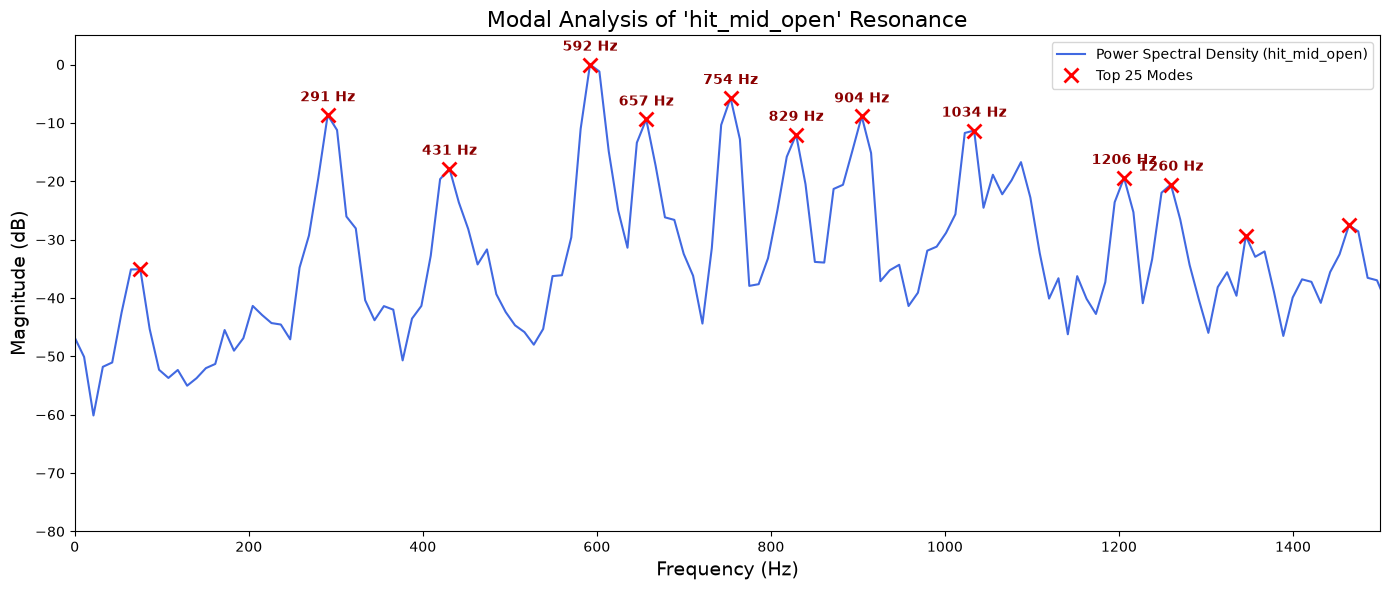

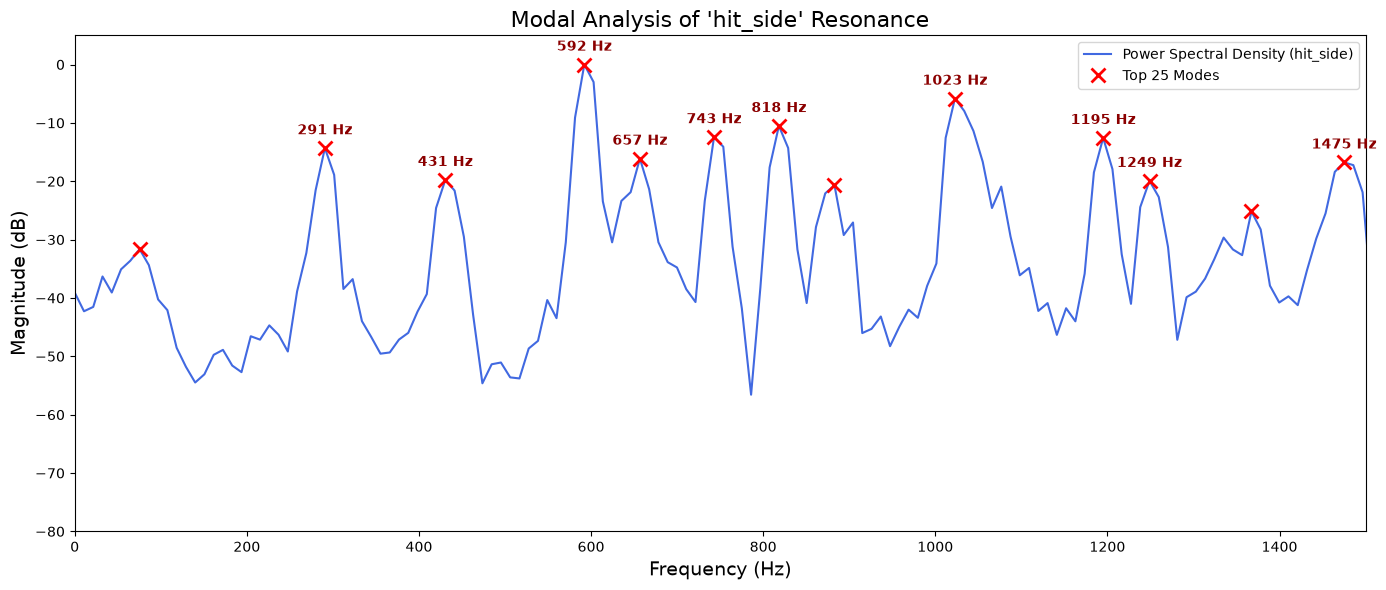

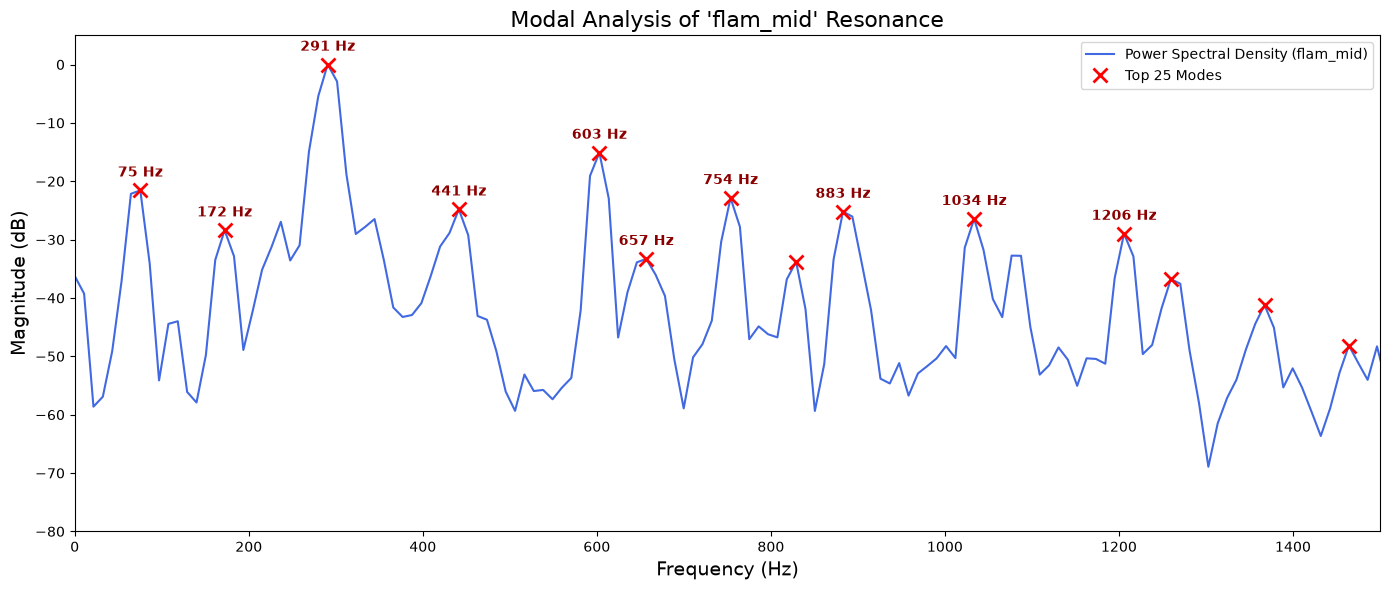

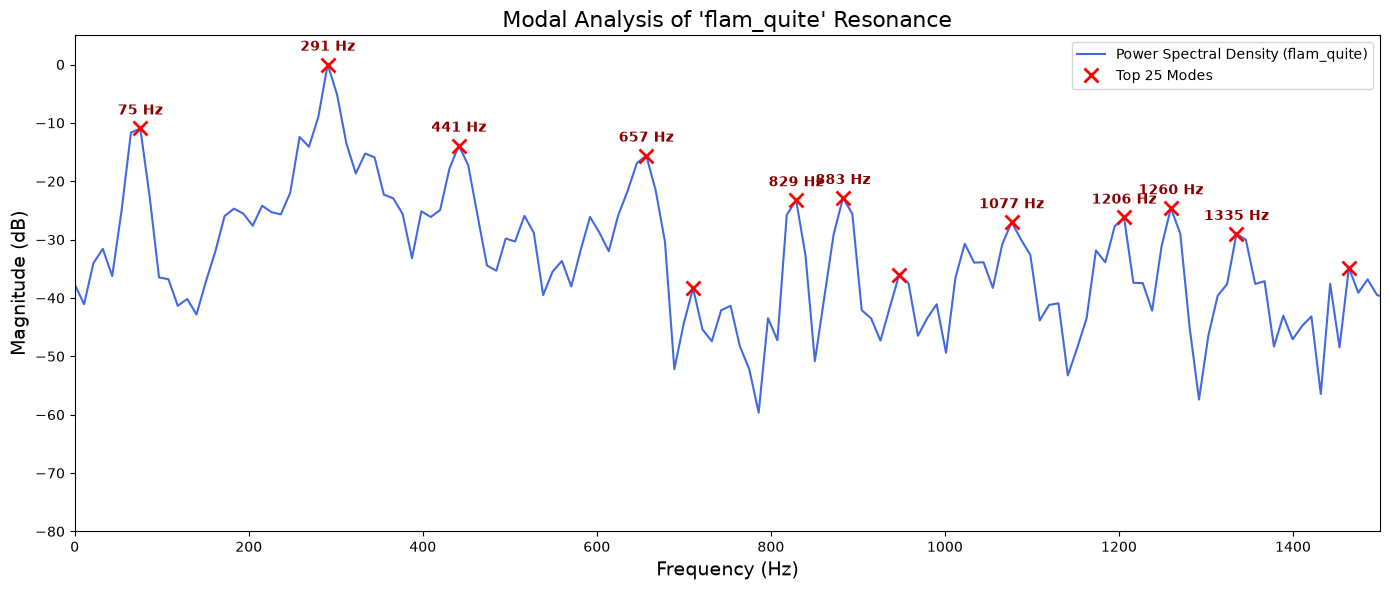

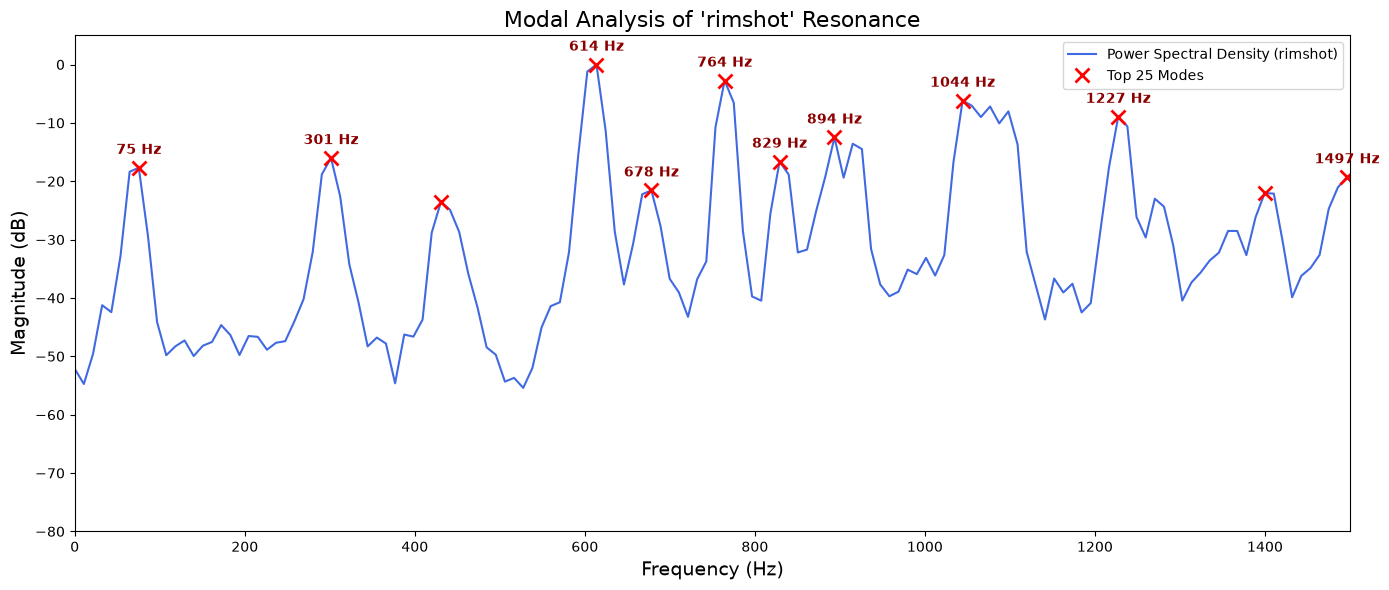

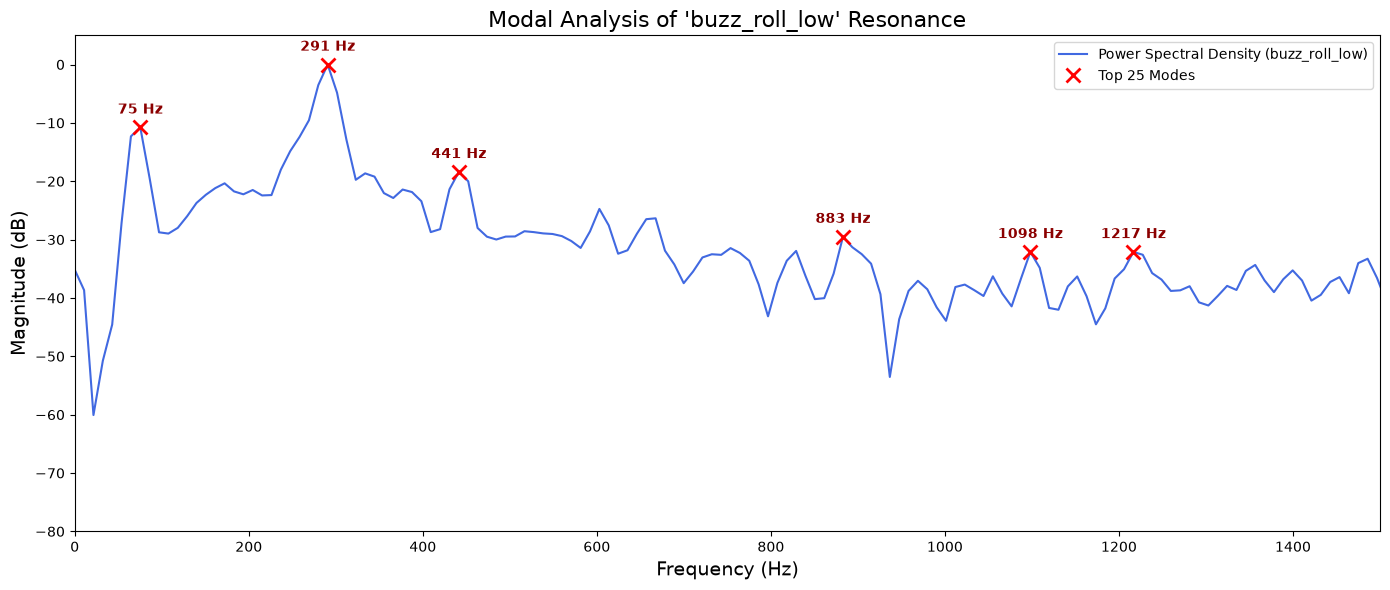

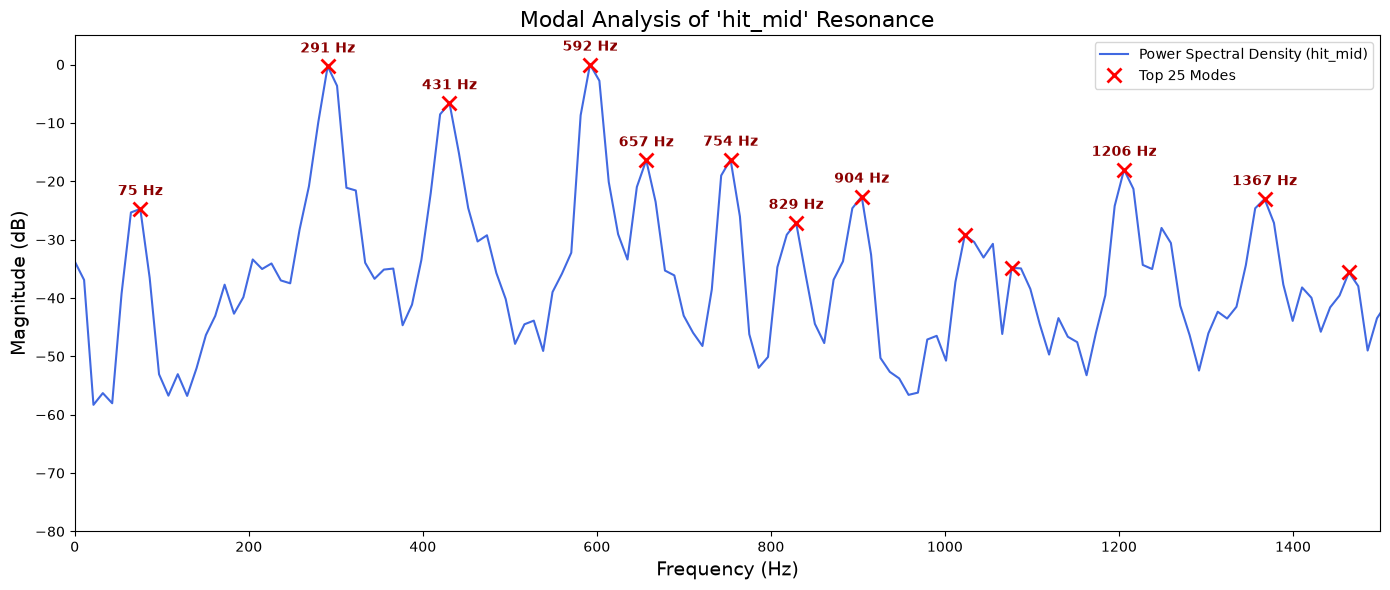

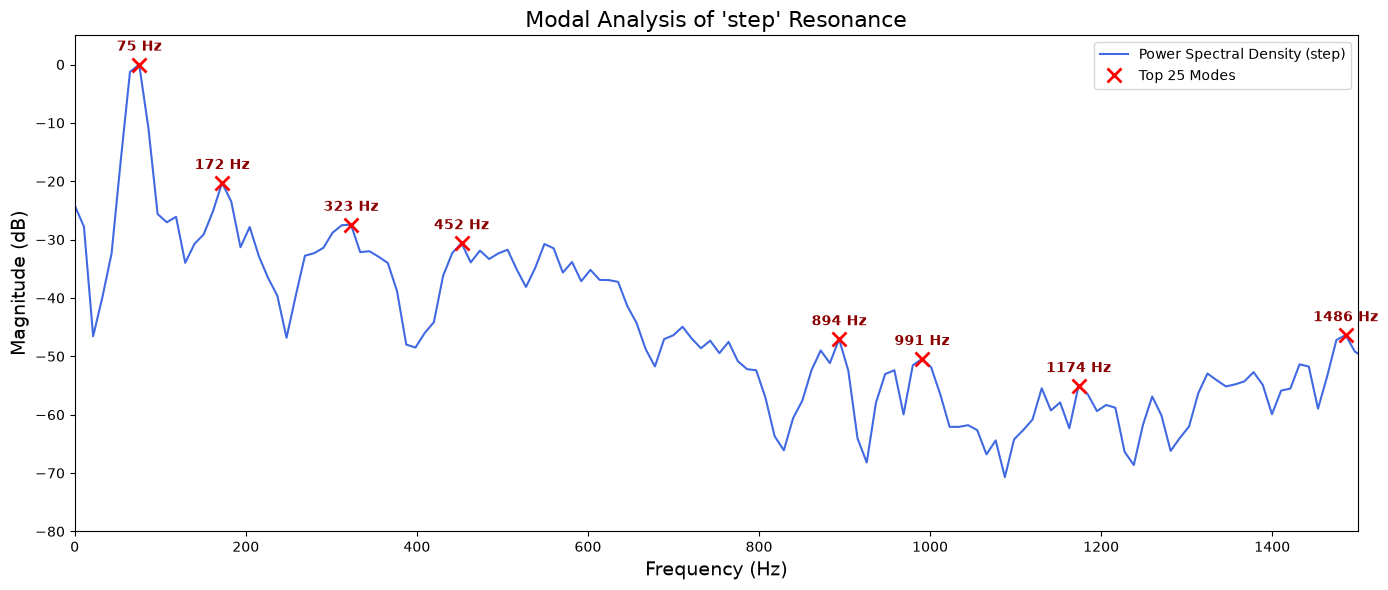

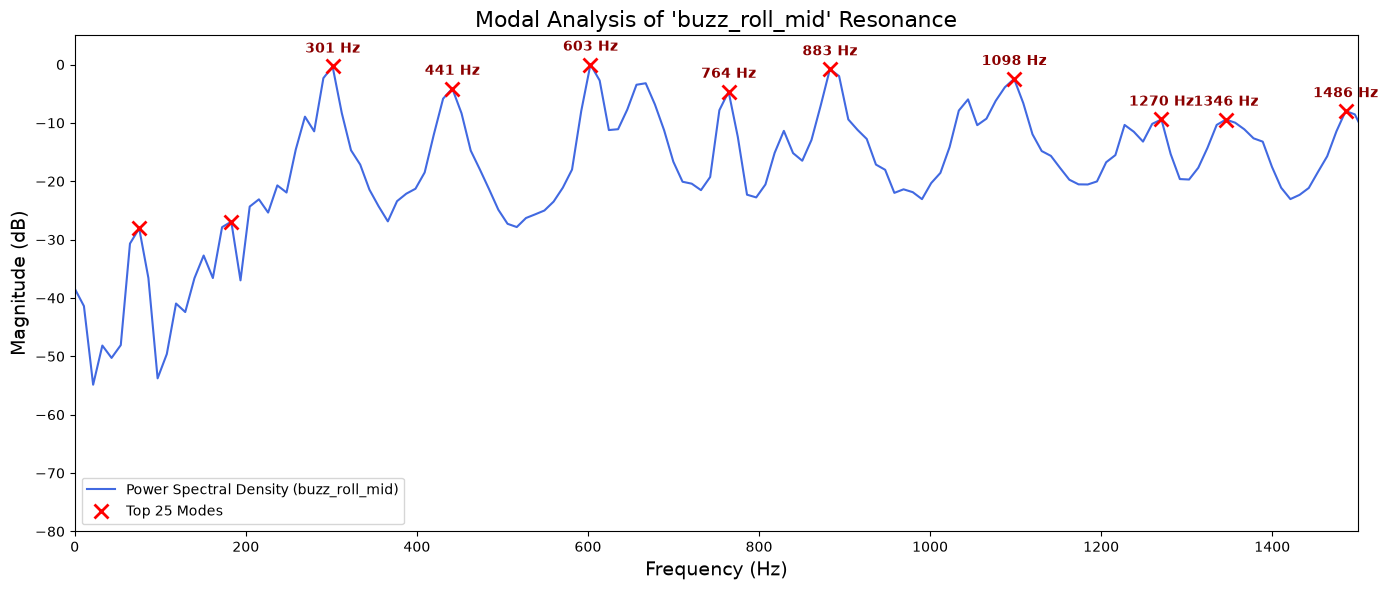

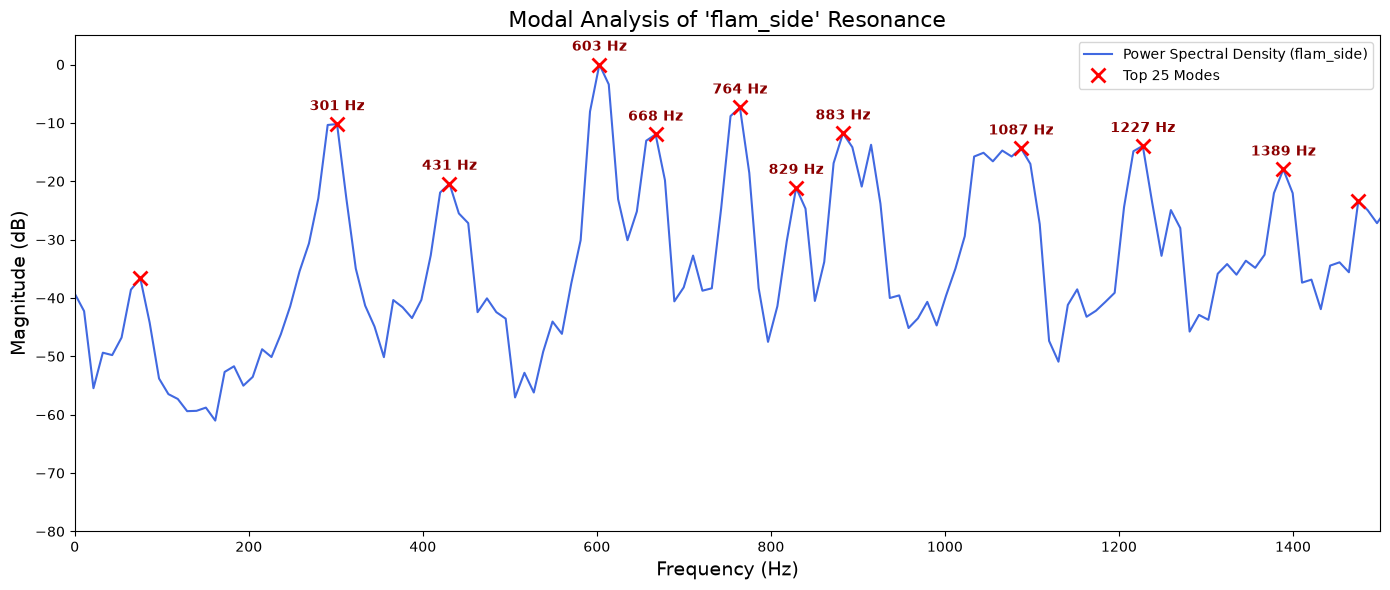

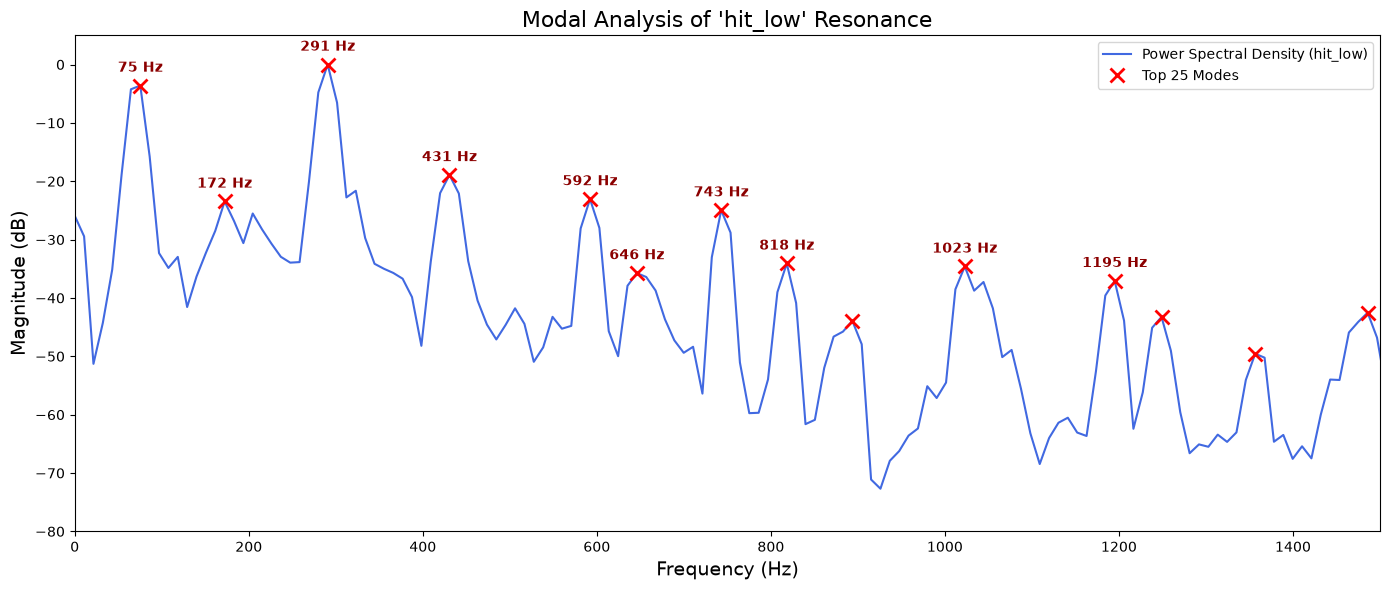

In [3]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import librosa
from scipy.signal import find_peaks, welch

NUM_MODES = 25
ANNOTATE_TOP = 10  # Only annotate the text for the loudest 10 to prevent visual clutter

for stroke in stroke_classes:
    wav_files = glob.glob(os.path.join(data_dir, stroke, "*.wav"))
    if not wav_files:
        continue
        
    # Load and isolate the decay phase[cite: 4]
    y, sr = librosa.load(wav_files[0], sr=44100)
    y, _ = librosa.effects.trim(y, top_db=30)
    transient_samples = int(0.05 * sr)
    y_decay = y[transient_samples:]
    
    if len(y_decay) == 0:
        continue
        
    # Compute Power Spectral Density[cite: 4]
    freqs, psd = welch(y_decay, fs=sr, nperseg=4096)
    psd_db = 10 * np.log10(psd / np.max(psd)) 
    
    # Find and sort peaks[cite: 4]
    peaks, properties = find_peaks(psd_db, prominence=10, distance=5)
    sorted_indices = np.argsort(psd_db[peaks])[::-1]
    dominant_peaks = peaks[sorted_indices][:NUM_MODES] 
    
    # Create the plot[cite: 4]
    plt.figure(figsize=(14, 6))
    plt.plot(freqs, psd_db, color='royalblue', label=f'Power Spectral Density ({stroke})')
    
    # Highlight all 25 discovered peaks[cite: 4]
    plt.plot(freqs[dominant_peaks], psd_db[dominant_peaks], "rx", markersize=10, markeredgewidth=2, label=f'Top {NUM_MODES} Modes')
    
    # Annotate only the top N frequencies to avoid overlapping text
    top_annotations = peaks[sorted_indices][:ANNOTATE_TOP]
    for peak_idx in top_annotations:
        plt.annotate(f"{freqs[peak_idx]:.0f} Hz", 
                     (freqs[peak_idx], psd_db[peak_idx]), 
                     textcoords="offset points", 
                     xytext=(0,10), 
                     ha='center', fontsize=10, fontweight='bold', color='darkred')

    plt.title(f"Modal Analysis of '{stroke}' Resonance", fontsize=16)
    plt.xlabel("Frequency (Hz)", fontsize=14)
    plt.ylabel("Magnitude (dB)", fontsize=14)
    plt.xlim(0, 1500) # Zoom in on the main ringing frequencies[cite: 4]
    plt.ylim(-80, 5)
    plt.legend()
    plt.tight_layout()
    plt.show()